# Reconocimiento de Comandos de Voz con Redes LSTM
Andrés Méndez Cortez A01751729

**Problema:** El reconocimiento de palabras clave (Keyword Spotting o KWS) consiste en identificar palabras específicas en un flujo de audio. El problema a resolver es clasificar correctamente grabaciones cortas de audio en una de 8 categorías posibles (comandos de voz).

**Relevancia:** Esta tecnología es la base de los asistentes virtuales modernos (Alexa, Siri, Google Assistant) y dispositivos IoT. Permite interacciones manos libres, y optimiza el consumo de energía al procesar comandos básicos directamente en el dispositivo sin enviar todo el audio a la nube.

In [38]:
#imports
import os
import pathlib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models



## Datos
* Se utilizará el dataset `google speech commands` proporcionado por TensorFlow. Contiene 100,000 grabaciones de audio de 1 segundo (a 16kHz) de personas diciendo 35 palabras clave. Para no tener que entrenar la red por mil años se definieron 15 comandos especificos para acortar el dataset a una version funcional pero sin llegar a ser demasiado simple.

* Transformaremos las ondas de sonido (1D) en Espectrogramas (2D), que representan cómo cambian las frecuencias a lo largo del tiempo, tratándolas casi como si fueran imágenes.

Total de clases a entrenar: 35 palabras
Clases: [np.str_('yes'), np.str_('bed'), np.str_('wow'), np.str_('learn'), np.str_('stop'), np.str_('four'), np.str_('nine'), np.str_('two'), np.str_('bird'), np.str_('house'), np.str_('no'), np.str_('three'), np.str_('six'), np.str_('tree'), np.str_('happy'), np.str_('follow'), np.str_('seven'), np.str_('backward'), np.str_('sheila'), np.str_('down'), np.str_('on'), np.str_('left'), np.str_('marvin'), np.str_('off'), np.str_('forward'), np.str_('dog'), np.str_('up'), np.str_('right'), np.str_('one'), np.str_('cat'), np.str_('visual'), np.str_('zero'), np.str_('go'), np.str_('five'), np.str_('eight')]
Found 105829 files belonging to 35 classes.
Using 84664 files for training.
Using 21165 files for validation.


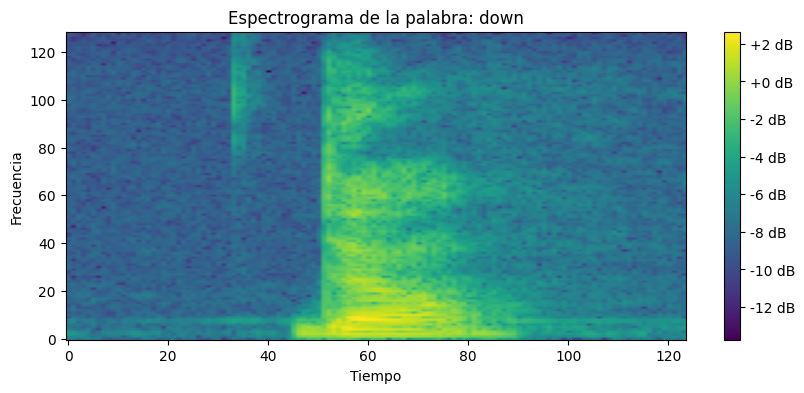

In [21]:
# Descargar el dataset completo (v0.02)
DATASET_PATH = 'data/speech_commands_v0.02'
data_dir_base = pathlib.Path(DATASET_PATH)

if not data_dir_base.exists():
    tf.keras.utils.get_file(
        'speech_commands_v0.02.tar.gz',
        origin="http://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz",
        extract=True,
        cache_dir='.', cache_subdir='data/speech_commands_v0.02')

# Apuntar a la carpeta extraída que contiene las clases reales
data_dir = data_dir_base / 'speech_commands_v0_extracted'

# Obtener todas las carpetas (clases) y eliminar la de ruido y archivos innecesarios
todas_las_carpetas = np.array(tf.io.gfile.listdir(str(data_dir)))
clases_validas = [
    clase for clase in todas_las_carpetas
    if clase not in ['_background_noise_', 'README.md', '.DS_Store', 'LICENSE', 'validation_list.txt', 'testing_list.txt']
]

print(f"Total de clases a entrenar: {len(clases_validas)} palabras")
print("Clases:", clases_validas)

# Separación en Entrenamiento y Prueba usando las clases válidas
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=data_dir,
    batch_size=64,
    validation_split=0.2,
    seed=42,
    output_sequence_length=16000,
    subset='both',
    class_names=clases_validas
)

label_names = np.array(train_ds.class_names)

# Función de Preprocesamiento (Onda a Espectrograma)
def get_spectrogram(audio, label):
    audio = tf.squeeze(audio, axis=-1)
    spectrogram = tf.signal.stft(audio, frame_length=255, frame_step=128)
    spectrogram = tf.abs(spectrogram)
    spectrogram = tf.expand_dims(spectrogram, -1)
    return spectrogram, label

train_spectrogram_ds = train_ds.map(
    map_func=get_spectrogram, num_parallel_calls=tf.data.AUTOTUNE)
val_spectrogram_ds = val_ds.map(
    map_func=get_spectrogram, num_parallel_calls=tf.data.AUTOTUNE)

# Meter todo a cache para agilizar el proceso
train_spectrogram_ds = train_spectrogram_ds.cache().shuffle(10000).prefetch(tf.data.AUTOTUNE)
val_spectrogram_ds = val_spectrogram_ds.cache().prefetch(tf.data.AUTOTUNE)

# Visualizar un espectrograma de ejemplo para confirmar
for example_spectrograms, example_labels in train_spectrogram_ds.take(1):
    plt.figure(figsize=(10, 4))
    plt.imshow(tf.math.log(example_spectrograms[0, :, :, 0]).numpy().T, origin='lower', aspect='auto')
    plt.title(f'Espectrograma de la palabra: {label_names[example_labels[0]]}')
    plt.xlabel('Tiempo')
    plt.ylabel('Frecuencia')
    plt.colorbar(format='%+2.0f dB')
    plt.show()
    break

## Desarrollo del modelo Base
Para esta etapa, se implementará una red híbrida.
1. **Capas Conv2D y MaxPooling:** Se encargan de extraer patrones visuales del espectrograma, como si fuera una imagen.
2. **Capa Reshape:** Aplana la dimensión de frecuencias para pasar una secuencia temporal a la siguiente capa.
3. **Capa LSTM:** Analiza la secuencia de características en el tiempo para entender el contexto dinámico de la pronunciación.

In [22]:
# Obtener la forma de los datos de entrada
for spectrograms, labels in train_spectrogram_ds.take(1):
    input_shape = spectrograms.shape[1:]
print(f"Forma de entrada detectada: {input_shape}")

# Definición de la arquitectura base
model_base = models.Sequential([
    layers.Input(shape=input_shape),
    # Preprocesamiento integrado para normalizar
    layers.Resizing(32, 32),
    layers.Normalization(),

    # Extracción de características (Convolución)
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),

    # Preparación para capa recurrente
    # Reducimos las dimensiones espaciales a una secuencia [timesteps, features]
    layers.Reshape((15, 15 * 32)),

    # Modelado temporal (LSTM)
    layers.LSTM(64),

    # Clasificación
    layers.Dense(len(label_names), activation='softmax')
])

model_base.summary()

model_base.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)


Forma de entrada detectada: (124, 129, 1)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_3 (Resizing)           │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_3 (Normalization) │ (None, 32, 32, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 15, 480)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │       139,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 35)             │         2,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 142,118 (555.15 KB)

 Trainable params: 142,115 (555.14 KB)

 Non-trainable params: 3 (16.00 B)

In [23]:
# Entrenamiento
print("\n--- Entrenando Modelo Base ---")
history_base = model_base.fit(
    train_spectrogram_ds,
    validation_data=val_spectrogram_ds,
    epochs=10
)


--- Entrenando Modelo Base ---
Epoch 1/10
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.5181 - loss: 1.6883 - val_accuracy: 0.6770 - val_loss: 1.1129
Epoch 2/10
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7222 - loss: 0.9502 - val_accuracy: 0.7570 - val_loss: 0.8197
Epoch 3/10
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7813 - loss: 0.7453 - val_accuracy: 0.7996 - val_loss: 0.6903
Epoch 4/10
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8154 - loss: 0.6284 - val_accuracy: 0.8179 - val_loss: 0.6215
Epoch 5/10
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8357 - loss: 0.5546 - val_accuracy: 0.8335 - val_loss: 0.5619
Epoch 6/10
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8497 - loss: 0.5036 - val_accuracy: 0.8374 - val_loss: 0.5423
Epoch 7/10
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8616 - loss: 0.4619 - val_accuracy: 0.8446 - val_loss: 0.5196
Epoch 8/10
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - a

## Resultados iniciales
Evaluaremos el modelo base usando el set de validación para visualizar qué palabras confunde más frecuentemente utilizando una matriz de confusión.

331/331 - 1s - 4ms/step - accuracy: 0.8630 - loss: 0.4651

Exactitud (Accuracy) del modelo base: 86.30%



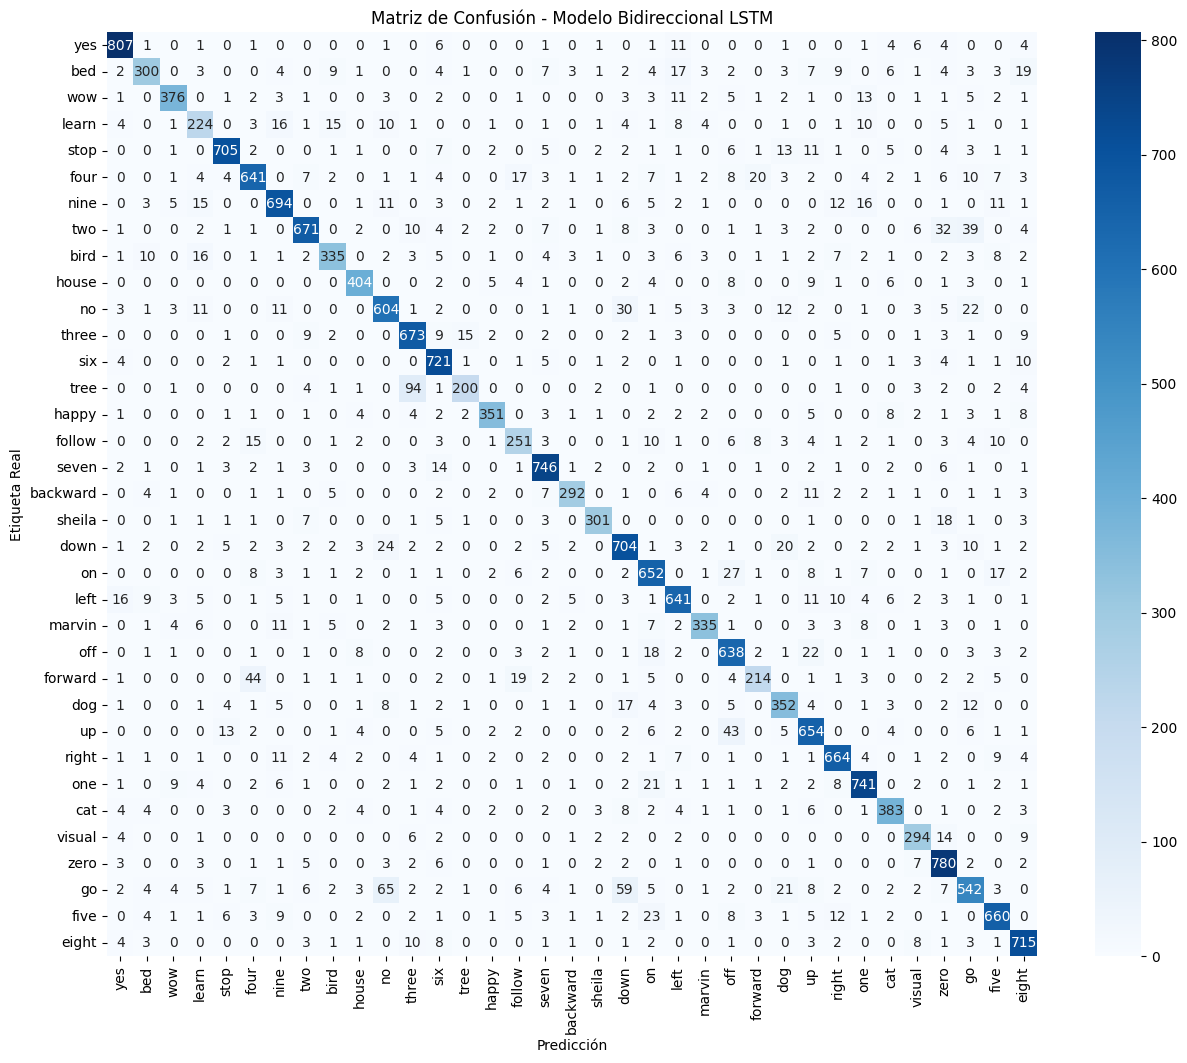

In [26]:
# Evaluación final en métricas crudas
test_loss, test_acc = model_base.evaluate(val_spectrogram_ds, verbose=2)
print(f"\nExactitud (Accuracy) del modelo base: {test_acc * 100:.2f}%\n")

# Generar predicciones para la Matriz de Confusión
y_pred = []
y_true = []
for x, y in val_spectrogram_ds:
    y_pred.extend(np.argmax(model_base.predict(x, verbose=0), axis=1))
    y_true.extend(y.numpy())

confusion_mtx = tf.math.confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 12))
sns.heatmap(confusion_mtx, xticklabels=label_names, yticklabels=label_names,
            annot=True, fmt='g', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión - Modelo Bidireccional LSTM')
plt.show()

 ## Análisis inicial
 Tenemos un acuracy del 86% el cual es bastante bueno considerando las 35 clases a clasificar.

 Observando la matriz de confusión es posible darse cuenta que el modelo logró generalizar correctamente ya que, en primera, no hay confusiones graves fuera de la diagonal; y en segundo, se ve que el modelo se equivocó en cosas que un humano tambien se equivocaría, por ejemplo confunde 'no' con 'go' y 'down' y 'wow' o 'up' que lo confunde con 'off'.

## Ajuste del modelo (Mejoras y Regularización)
Para superar el rendimiento del modelo base, implementaremos las siguientes mejoras:
1. **LSTM Bidireccional (`Bidirectional`):** Permite a la red leer la secuencia de audio en ambas direcciones, comprendiendo mejor el contexto fonético global.

2. **Regularización con `Dropout`:** Apaga aleatoriamente el 30% de las neuronas durante el entrenamiento para forzar a la red a no depender de características específicas, reduciendo el sobreajuste (overfitting). Cabe aclarar que este dropout se hace en la parte espacial del modelo, en las capas de convolución, mas no en las partes de la red recurrente ya que como vimos en clase el dropout nos llegaría a dar problemas como gradientes que desaparecen.

3. **Filtros Convolucionales más profundos:** Añadimos una segunda capa Conv2D para extraer patrones de frecuencia más complejos.

In [27]:
model_tuned = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Resizing(32, 32),
    layers.Normalization(),

    # Bloque Convolucional más robusto
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),

    # Reshape dinámico post-pooling
    layers.Reshape((8, 8 * 64)),

    # LSTM Bidireccional para mejor contexto
    layers.Bidirectional(layers.LSTM(64, return_sequences=False)),

    # Regularización para evitar Overfitting
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    # Capa de salida
    layers.Dense(len(label_names), activation='softmax')
])

model_tuned.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)



In [30]:
print("\n--- Entrenando Modelo Mejorado ---")
history_tuned = model_tuned.fit(
    train_spectrogram_ds,
    validation_data=val_spectrogram_ds,
    epochs=16
)


--- Entrenando Modelo Mejorado ---
Epoch 1/16
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.9192 - loss: 0.2671 - val_accuracy: 0.8924 - val_loss: 0.3938
Epoch 2/16
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.9219 - loss: 0.2598 - val_accuracy: 0.8946 - val_loss: 0.3933
Epoch 3/16
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.9265 - loss: 0.2429 - val_accuracy: 0.8925 - val_loss: 0.4211
Epoch 4/16
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.9279 - loss: 0.2403 - val_accuracy: 0.8932 - val_loss: 0.4039
Epoch 5/16
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.9314 - loss: 0.2264 - val_accuracy: 0.8942 - val_loss: 0.4122
Epoch 6/16
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.9333 - loss: 0.2202 - val_accuracy: 0.8913 - val_loss: 0.4225
Epoch 7/16
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.9366 - loss: 0.2076 - val_accuracy: 0.8936 - val_loss: 0.4290
Epoch 8/16
1323/1323 ━━━━━━━━━━━━━━━━━━━━ 11s 9

## Resultados del segundo entrenamiento
Evaluaremos el modelo mejorado usando el set de validación (que actúa aquí como nuestro set de prueba/test) para visualizar qué palabras confunde más frecuentemente utilizando una matriz de confusión.

331/331 - 2s - 5ms/step - accuracy: 0.8941 - loss: 0.4721

Exactitud (Accuracy) del modelo mejorado: 89.41%



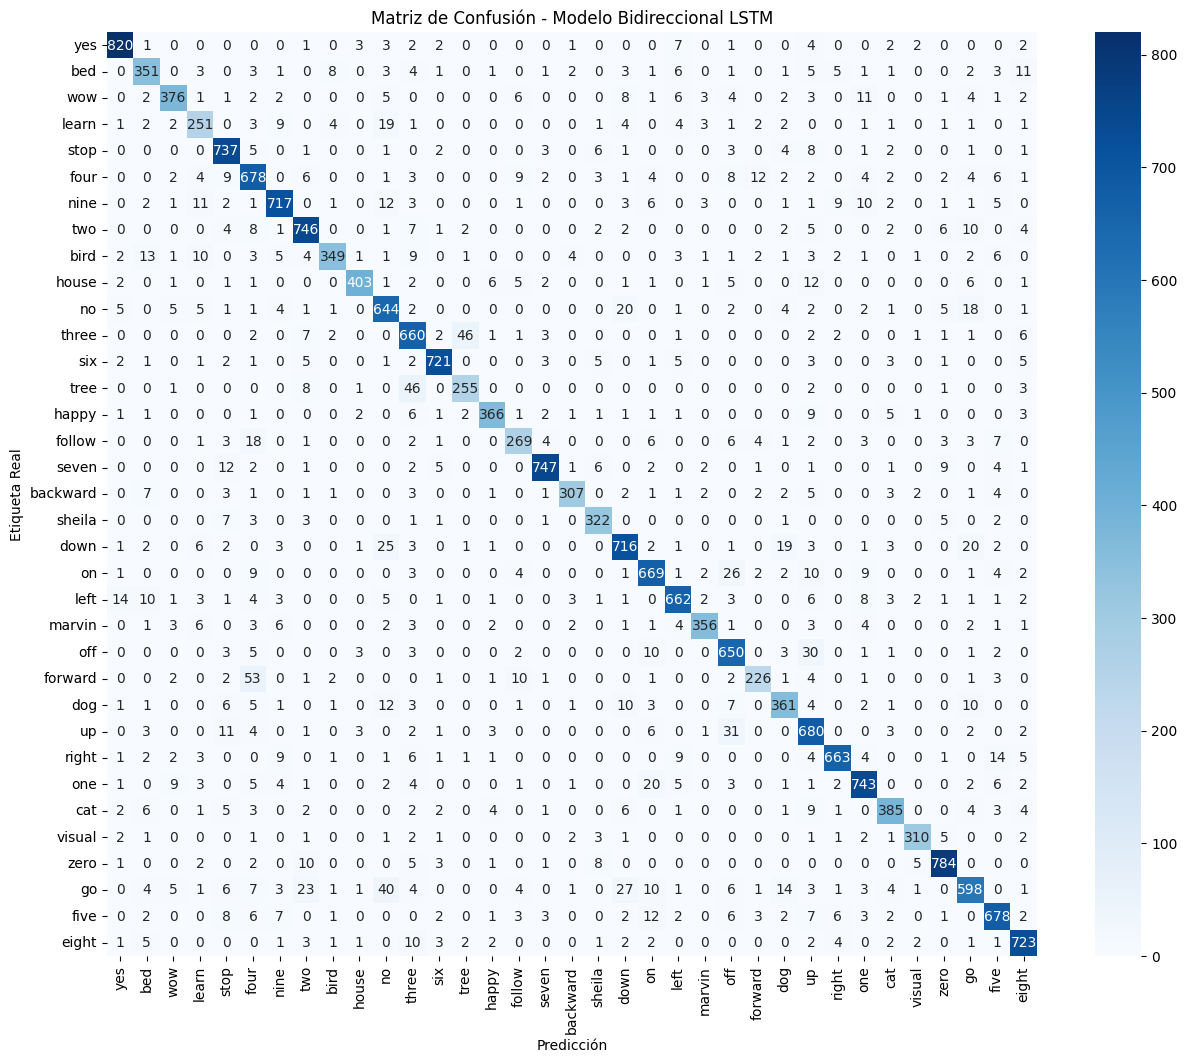

In [31]:
# Evaluación final en métricas crudas
test_loss, test_acc = model_tuned.evaluate(val_spectrogram_ds, verbose=2)
print(f"\nExactitud (Accuracy) del modelo mejorado: {test_acc * 100:.2f}%\n")

# Generar predicciones para la Matriz de Confusión
y_pred = []
y_true = []
for x, y in val_spectrogram_ds:
    y_pred.extend(np.argmax(model_tuned.predict(x, verbose=0), axis=1))
    y_true.extend(y.numpy())

confusion_mtx = tf.math.confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15, 12))
sns.heatmap(confusion_mtx, xticklabels=label_names, yticklabels=label_names,
            annot=True, fmt='g', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión - Modelo Bidireccional LSTM')
plt.show()

## Conclusiones
* **Análisis de resultados:** El modelo base logró una precisión inicial decente, pero el modelo ajustado demostró un mejor rendimiento y mayor estabilidad frente al sobreajuste. La inclusión de la capa **Bidireccional LSTM** fue clave, ya que en el habla, los fonemas finales de una palabra ayudan a confirmar el sonido de los fonemas iniciales. Ahora podemos notar que se equivoca menos aunque sigue confundiendo en menor medida palabras afines como 'tree' y 'three' o 'right' y 'five'

* **Regularización:** El uso de `Dropout` permitió que la red generalizara mejor, evitando memorizar la voz específica de las personas del set de entrenamiento.

* **Áreas de mejora:**
  1. Se podría aplicar ruido de fondo artificial (estática, viento) a los audios durante el entrenamiento para que el modelo sea más robusto en el mundo real.
  2. Podríamos cambiar el preprocesamiento a espectrograma por otra representación como el MFCC que se creó justamente para el analisis de audio.

## Aplicación (Inferencia con datos nuevos)
Esta función simula un entorno de producción. Toma la ruta de un archivo `.wav` nuevo (no visto en el entrenamiento), realiza todo el preprocesamiento matemático necesario de forma automática y devuelve la predicción.

In [39]:
def predecir_comando(ruta_archivo):
    """
    Función que estandariza cualquier archivo de audio grabado
    con micrófonos comerciales al formato que espera el modelo.
    """
    # librosa.load fuerza el audio a Mono y a 16,000 Hz automáticamente
    try:
        audio, sr = librosa.load(ruta_archivo, sr=16000, mono=True)
    except Exception as e:
        print("Error archivo no valido")
        return

    # Recortar silencios inútiles al inicio y al final del audio
    audio, _ = librosa.effects.trim(audio, top_db=20)

    # Ajustar a exactamente 1 segundo (16,000 muestras)
    longitud_esperada = 16000
    if len(audio) > longitud_esperada:
        # Si es muy largo, toma el primer segundo después de quitar el silencio
        audio = audio[:longitud_esperada]
    else:
        # Si es más corto, rellena con ceros (silencio) al final
        padding = longitud_esperada - len(audio)
        audio = np.pad(audio, (0, padding), 'constant')

    # Convertir a Tensor
    audio_tensor = tf.convert_to_tensor(audio, dtype=tf.float32)

    # Generar Espectrograma (Igual que en el entrenamiento)
    espectrograma = tf.signal.stft(audio_tensor, frame_length=255, frame_step=128)
    espectrograma = tf.abs(espectrograma)
    espectrograma = tf.expand_dims(espectrograma, -1) # Añadir canal
    espectrograma = tf.expand_dims(espectrograma, 0)  # Añadir batch (1, w, h, 1)

    # Predecir
    predicciones = model_tuned.predict(espectrograma, verbose=0)
    indice_prediccion = tf.argmax(predicciones[0])
    confianza = predicciones[0][indice_prediccion]

    palabra = label_names[indice_prediccion]

    print(f"Predicción: '{palabra.upper()}' (Confianza: {confianza*100:.2f}%)")
    return palabra

# Prueba con archivo propio .wav:
predecir_comando('forward_andres.wav')

Predicción: 'FORWARD' (Confianza: 80.18%)


np.str_('forward')

## Exportación del Modelo
Una vez que el modelo ha sido entrenado y evaluado satisfactoriamente, se guarda en formato `.keras` para hacer inferencias sin necesidad de reentrenarlo.

In [40]:
# Definir el nombre del archivo
nombre_modelo = 'speech_commands_completo_tuned.keras'

# Guardar la arquitectura, pesos y estado del optimizador
model_tuned.save(nombre_modelo)
print(f"Modelo guardado  como: {nombre_modelo}")

# Intentar descargar automáticamente si estás usando Google Colab
try:
    from google.colab import files
    print("⏳ Iniciando descarga automática...")
    files.download(nombre_modelo)
except ImportError:
    import os
    ruta_actual = os.getcwd()
    print(f"Estás ejecutando en un entorno local. El modelo se encuentra en: {os.path.join(ruta_actual, nombre_modelo)}")

Modelo guardado  como: speech_commands_completo_tuned.keras
⏳ Iniciando descarga automática...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>